# LLM judge: exact first-error evaluation

Full-run CSVs (`runs/llm_judge_qwen35_*_full_arm.csv`), no inference. All reported percentages use the complete trace denominator: malformed/out-of-range answers are **wrong**, including on clean traces. The binary MR-GSM8K MCC counts invalid responses as incorrect binary predictions; a valid but wrong error *location* still counts as identifying an erroneous trace. The published numbers are baselines from different models/prompts and are not replications. All paper scores below are percentages (MCC multiplied by 100).

In [20]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from experiment_setup.judge_metrics import summarize, processbench_average

RUNS = Path('runs') if Path('runs').exists() else Path('final/runs')
MODELS = ['4B', '9B', '27B']
BENCHMARKS = ['MR-GSM8K', 'BIG-Bench-Mistake', 'ProcessBench']
results = {}
for model in MODELS:
    path = RUNS / f'llm_judge_qwen35_{model.lower()}_full_arm.csv'
    frame = pd.read_csv(path, usecols=['benchmark', 'task', 'uid', 'label', 'prediction', 'parse_error'])
    assert frame.groupby('benchmark').size().to_dict() == dict(zip(BENCHMARKS, [2999, 2186, 3400])), path
    assert not frame.duplicated(['benchmark', 'task', 'uid']).any(), path
    results[model] = frame


def paper_comparison(ax, paper, ours, source, metric, max_y=100):
    """Ascending score order, with paper/ours colors and one legend per chart."""
    values = pd.Series(paper | ours).sort_values(kind='stable')
    colors = ['tab:gray' if name in paper else 'tab:blue' for name in values.index]
    values.plot.barh(ax=ax, color=colors)
    ax.set(xlabel=metric, ylabel='', xlim=(min(0, values.min()), max_y))
    ax.legend(handles=[Patch(color='tab:gray', label=source),
                       Patch(color='tab:blue', label='Ours')], loc='lower right')


## Trace accuracy

Overall = exact first-error location (or NONE); clean = exact NONE on error-free traces; error = exact first error on erroneous traces. Invalid outputs are incorrect in each metric.

In [2]:
overview = pd.concat([summarize(frame).assign(model=model) for model, frame in results.items()], ignore_index=True)
overview['benchmark'] = pd.Categorical(overview.benchmark, BENCHMARKS, ordered=True)
overview = overview.sort_values(['benchmark', 'model'])
display(overview[['benchmark', 'model', 'n', 'errors', 'unparseable', 'accuracy', 'correct_accuracy', 'error_accuracy']].style.format({
    'accuracy':'{:.1%}', 'correct_accuracy':'{:.1%}', 'error_accuracy':'{:.1%}'}))


,benchmark,model,n,errors,unparseable,accuracy,correct_accuracy,error_accuracy
6,MR-GSM8K,27B,2999,1571,0,72.1%,84.5%,60.8%
0,MR-GSM8K,4B,2999,1571,7,55.4%,64.2%,47.3%
3,MR-GSM8K,9B,2999,1571,17,63.5%,85.0%,43.9%
7,BIG-Bench-Mistake,27B,2186,1708,0,43.4%,22.0%,49.4%
1,BIG-Bench-Mistake,4B,2186,1708,33,24.6%,21.8%,25.4%
4,BIG-Bench-Mistake,9B,2186,1708,38,24.6%,24.5%,24.6%
8,ProcessBench,27B,3400,2221,11,68.9%,74.7%,65.9%
2,ProcessBench,4B,3400,2221,898,41.4%,44.7%,39.6%
5,ProcessBench,9B,3400,2221,4,61.4%,70.8%,56.3%


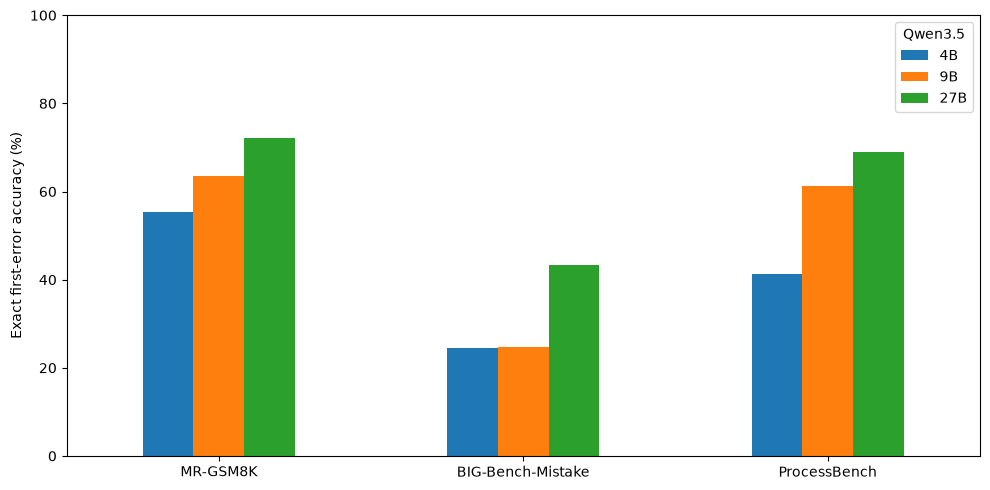

In [10]:
ax = overview.pivot(index='benchmark', columns='model', values='accuracy').reindex(index=BENCHMARKS, columns=MODELS).mul(100).plot.bar(figsize=(10, 5), rot=0)
ax.set(xlabel='', ylabel='Exact first-error accuracy (%)')
ax.legend(title='Qwen3.5')
ax.set_ylim(top=100)
plt.tight_layout()
plt.show()


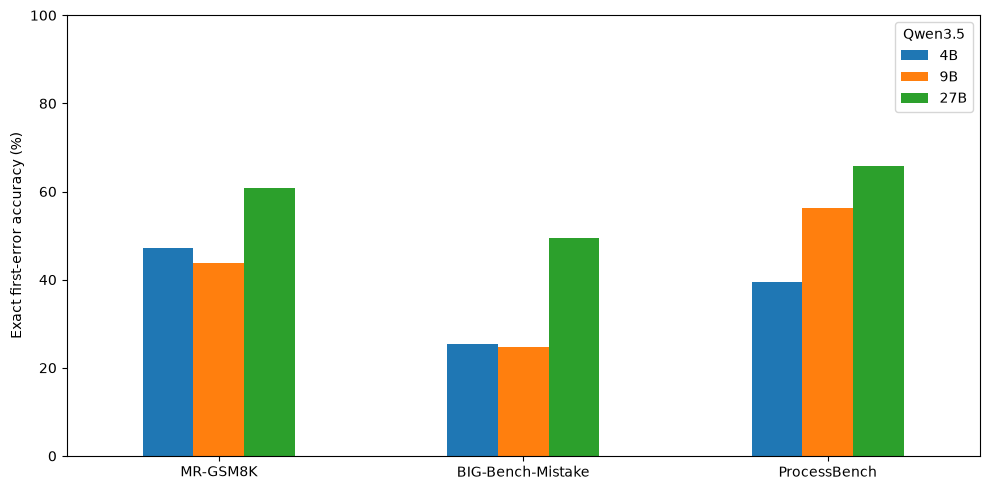

In [11]:
ax = overview.pivot(index='benchmark', columns='model', values='error_accuracy').reindex(index=BENCHMARKS, columns=MODELS).mul(100).plot.bar(figsize=(10, 5), rot=0)
ax.set(xlabel='', ylabel='Exact first-error accuracy (%)')
ax.legend(title='Qwen3.5')
ax.set_ylim(top=100)
plt.tight_layout()
plt.show()


## ProcessBench — Zheng et al. (2025), Table 3 (p. 7)

All **open-weight language models prompted as critics** from the paper (not PRMs or proprietary models) are shown. The paper calls the harmonic mean of *separate* clean/error exact-location accuracies “F1”. Its **Average** is the unweighted mean of the four split harmonic means, **not** pooled F1 or pooled harmonic mean. Only this benchmark-level average is plotted. Paper open-weight critic results use majority vote over eight samples (our runs use one response); prompts and model generations also differ.

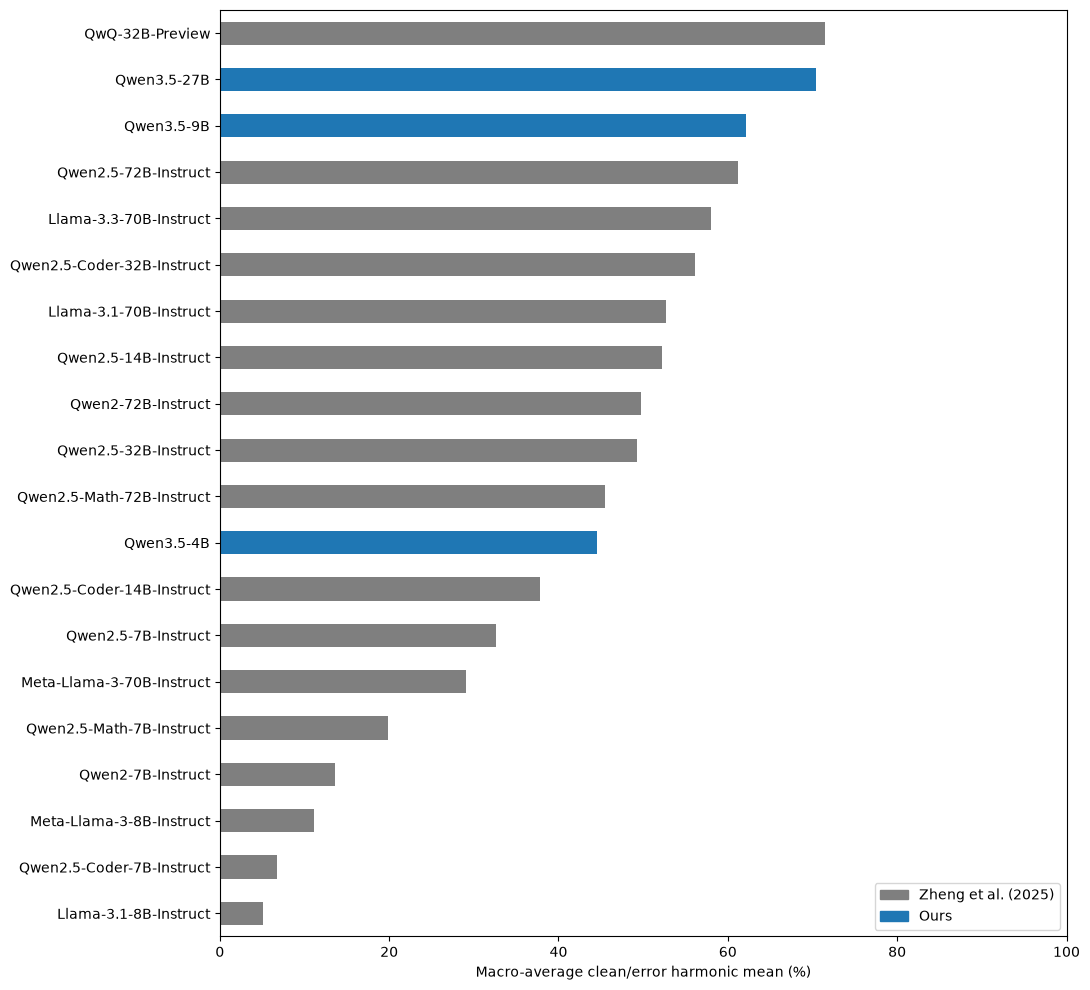

In [4]:
# Zheng et al. (2025), Table 3, Average column: open-weight critic LLMs only.
pb_paper = {
    'Meta-Llama-3-8B-Instruct': 11.1,
    'Meta-Llama-3-70B-Instruct': 29.1,
    'Llama-3.1-8B-Instruct': 5.1,
    'Llama-3.1-70B-Instruct': 52.7,
    'Llama-3.3-70B-Instruct': 58.0,
    'Qwen2.5-Math-7B-Instruct': 19.9,
    'Qwen2.5-Math-72B-Instruct': 45.5,
    'Qwen2.5-Coder-7B-Instruct': 6.7,
    'Qwen2.5-Coder-14B-Instruct': 37.8,
    'Qwen2.5-Coder-32B-Instruct': 56.1,
    'Qwen2-7B-Instruct': 13.6,
    'Qwen2-72B-Instruct': 49.8,
    'Qwen2.5-7B-Instruct': 32.6,
    'Qwen2.5-14B-Instruct': 52.2,
    'Qwen2.5-32B-Instruct': 49.3,
    'Qwen2.5-72B-Instruct': 61.2,
    'QwQ-32B-Preview': 71.5,
}
assert len(pb_paper) == 17
pb_ours = {f'Qwen3.5-{model}': processbench_average(frame) * 100
           for model, frame in results.items()}
fig, ax = plt.subplots(figsize=(11, 10))
paper_comparison(ax, pb_paper, pb_ours, 'Zheng et al. (2025)',
                 'Macro-average clean/error harmonic mean (%)')
plt.tight_layout()
plt.show()


## MR-GSM8K — paper Table 2 (p. 6), zero-shot k=0

Task 1: MCC of binary *process correctness*; our error-vs-clean encoding has the same MCC. Task 2: first-error accuracy over **all** erroneous traces. No error-reason comparison: our index-only judge does not give explanations. Paper uses a separate judgement field and a different prompt; here binary judgement is derived from the returned location. Negative MCC is retained (not clipped as in MR-Score).

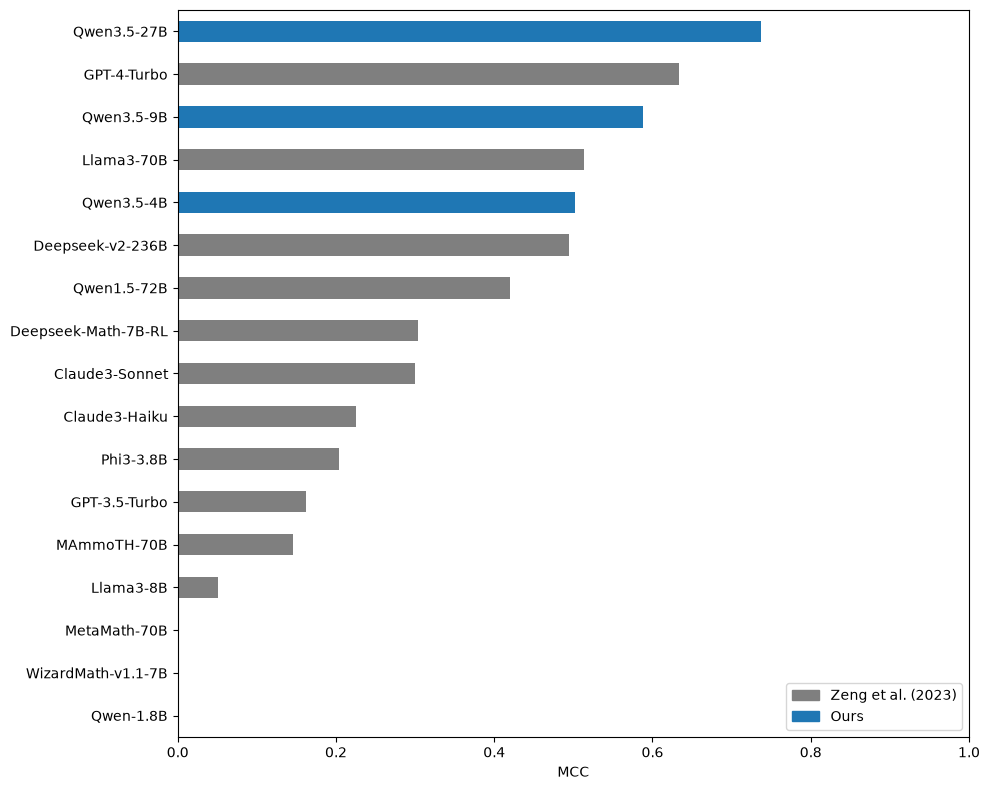

In [22]:
# Zeng et al. (2023), Table 2, zero-shot (k=0) Task 1 MCC and Task 2 accuracy.
mr_paper = pd.DataFrame.from_dict({
    'Qwen-1.8B': (0.0, 0.0),
    'Phi3-3.8B': (20.4, 32.9),
    'Deepseek-Math-7B-RL': (30.4, 9.8),
    'WizardMath-v1.1-7B': (0.0, 0.3),
    'Llama3-8B': (5.1, 29.1),
    'MAmmoTH-70B': (14.6, 3.9),
    'MetaMath-70B': (0.0, 0.1),
    'Llama3-70B': (51.3, 38.9),
    'Qwen1.5-72B': (42.0, 19.1),
    'Deepseek-v2-236B': (49.4, 26.8),
    'Claude3-Haiku': (22.5, 17.2),
    'GPT-3.5-Turbo': (16.2, 30.6),
    'Claude3-Sonnet': (30.0, 25.2),
    'GPT-4-Turbo': (63.3, 48.8),
}, orient='index', columns=['MCC', 'First-error accuracy'])
assert len(mr_paper) == 14
mr_paper = mr_paper / 100

mr_ours = overview[overview.benchmark == 'MR-GSM8K'].set_index('model')
# fig, axes = plt.subplots(1, 2, figsize=(20, 8))
# for ax, metric, field in zip(axes, mr_paper.columns, ['mr_mcc']):
#     paper = mr_paper[metric].to_dict()
#     ours = {f'Qwen3.5-{model}': 100 * mr_ours.loc[model, field] for model in MODELS}
#     paper_comparison(ax, paper, ours, 'Zeng et al. (2023)', f'{metric} (%)')
#     ax.set_title(metric)
# plt.tight_layout()
# plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
for metric, field in zip(mr_paper.columns, ['mr_mcc']):
    paper = mr_paper[metric].to_dict()
    ours = {f'Qwen3.5-{model}': mr_ours.loc[model, field] for model in MODELS}
    paper_comparison(ax, paper, ours, 'Zeng et al. (2023)', metric, max_y=1)
plt.tight_layout()
plt.show()


## BIG-Bench Mistake — paper Table 4 (p. 4), direct trace

Compare **exact first-error accuracy over all traces**, not weighted binary F1 (paper Table 5 predicts *final-answer correctness*, which is not the same as process correctness). The paper's “Overall” is the unweighted mean of the five task accuracies. We calculate the same macro average, but our Dyck task uses **all 986 traces** rather than the paper's 592-trace subsample (GPT-4-Turbo: 300), so the overall figures are **not** directly comparable. Paper uses three-shot, task-specific direct-trace prompts; our judge is zero-shot with a shared prompt.

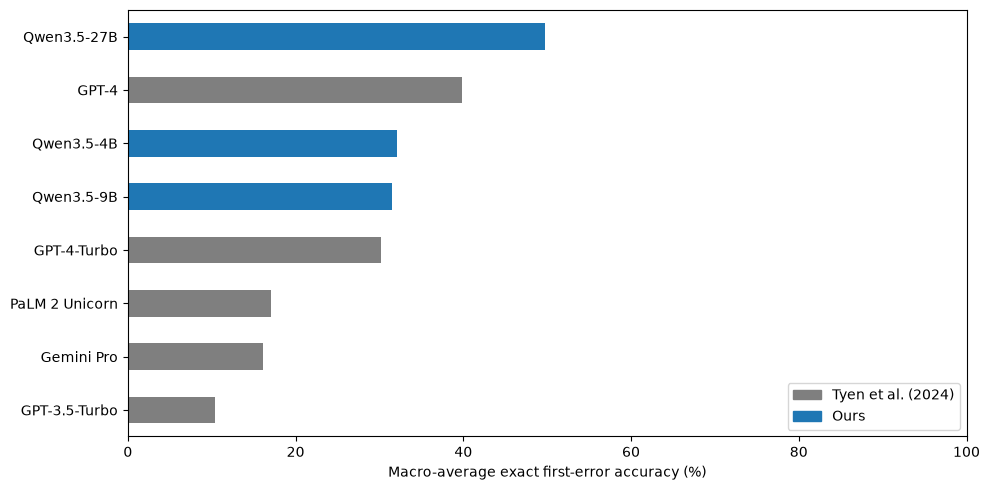

In [6]:
# Tyen et al. (2024), Table 4, Overall / Direct (trace) column: all five models.
bbm_paper = {
    'GPT-4-Turbo': 30.13,
    'GPT-4': 39.80,
    'GPT-3.5-Turbo': 10.44,
    'Gemini Pro': 16.14,
    'PaLM 2 Unicorn': 17.09,
}
assert len(bbm_paper) == 5
bbm_ours = {f'Qwen3.5-{model}': summarize(
    frame[frame.benchmark == 'BIG-Bench-Mistake'], ('task',)
).accuracy.mean() * 100 for model, frame in results.items()}
fig, ax = plt.subplots(figsize=(10, 5))
paper_comparison(ax, bbm_paper, bbm_ours, 'Tyen et al. (2024)',
                 'Macro-average exact first-error accuracy (%)')
plt.tight_layout()
plt.show()


In [ ]:
# Thesis figure: conditional exact accuracy separates localization from saying NONE.
out = Path('../thesis/chapters/results')
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, constrained_layout=True)
for ax, benchmark in zip(axes, BENCHMARKS):
    subset = overview[overview.benchmark == benchmark].set_index('model').reindex(MODELS)
    subset[['correct_accuracy', 'error_accuracy']].rename(columns={
        'correct_accuracy': 'Clean traces: NONE', 'error_accuracy': 'Error traces: first error'
    }).mul(100).plot.bar(ax=ax, rot=0, legend=False)
    ax.set(title=benchmark, xlabel='', ylabel='Exact accuracy (%)', ylim=(0, 100))
    ax.grid(axis='y', alpha=.2)
fig.legend(axes[0].get_legend_handles_labels()[0], ['Clean traces: NONE', 'Error traces: first error'],
           loc='lower center', ncol=2, bbox_to_anchor=(.5, -.12))
fig.savefig(out / 'judge-conditional-accuracy.png', dpi=220, bbox_inches='tight')
plt.show()